# Student Performance EDA
**Engagement 1 — County Education Office**

**Dataset:** `student_performance.csv` · 1,200 students · seed 55  
**Purpose:** Identify learners most at risk of poor performance and factors associated with better results to inform a county learner-support programme budget proposal.

---
### EDA Framework
This notebook follows five structured steps:  
1. **Structure** — grain, schema, data quality  
2. **Univariate** — distributions of individual variables  
3. **Bivariate** — pairwise relationships  
4. **Multivariate** — interactions across three or more dimensions  
5. **Hypotheses** — trend line, school-type gap, formal tests  

---
## 0 · Setup — Imports and Global Settings

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)

# Consistent style across all charts in this notebook
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
})

print("Libraries loaded.")
print(f"  pandas  {pd.__version__}")
print(f"  numpy   {np.__version__}")

Libraries loaded.
  pandas  3.1.1
  numpy   2.5.5


---
## 1 · Structure
**Goal:** Understand the grain of the data, the variables and their types, and confirm there are no data-quality issues before any analysis begins.

In [2]:
# Load dataset
df = pd.read_csv("student_performance.csv")

print("=" * 55)
print("DATASET OVERVIEW")
print("=" * 55)
print(f"Rows : {df.shape[0]:,}")
print(f"Cols : {df.shape[1]}")
print()
print(df.dtypes)
print()
df.head()

DATASET OVERVIEW
Rows : 1,200
Cols : 9

student_id           int64
county                 str
school_type            str
gender                 str
attendance_rate    float64
study_hours        float64
math               float64
english            float64
science            float64
dtype: object



,student_id,county,school_type,gender,attendance_rate,study_hours,math,english,science
0,1,Turkana,Private,M,0.77,6.5,81.0,71.0,73.0
1,2,Nyeri,Private,M,0.97,8.5,100.0,86.0,90.0
2,3,Nyeri,Private,F,0.98,8.0,82.0,89.0,90.0
3,4,Turkana,Public,M,0.93,6.0,83.0,91.0,72.0
4,5,Kisumu,Private,F,0.67,6.1,76.0,69.0,62.0


In [3]:
# Grain check: each row should be one unique student
n_unique_ids = df["student_id"].nunique()
print(f"Unique student_ids : {n_unique_ids}  (expected {len(df)})")
print(f"Duplicate rows     : {df.duplicated().sum()}")

# Missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Value ranges for key numeric columns
print("\nValue ranges:")
for col in ["attendance_rate", "study_hours", "math", "english", "science"]:
    print(f"  {col:<18} min={df[col].min():.2f}  max={df[col].max():.2f}")

Unique student_ids : 1200  (expected 1200)
Duplicate rows     : 0

Missing values per column:
student_id         0
county             0
school_type        0
gender             0
attendance_rate    0
study_hours        0
math               0
english            0
science            0
dtype: int64

Value ranges:
  attendance_rate    min=0.33  max=1.00
  study_hours        min=0.20  max=23.30
  math               min=37.00  max=100.00
  english            min=47.00  max=100.00
  science            min=35.00  max=100.00


In [4]:
# Categorical cardinalities
for col in ["county", "school_type", "gender"]:
    print(f"\n{col} ({df[col].nunique()} unique values):")
    print(df[col].value_counts(normalize=True).mul(100).round(1).to_string())


county (6 unique values):
county
Mombasa    17.7
Kisumu     17.3
Nyeri      16.9
Nakuru     16.8
Turkana    15.9
Nairobi    15.3

school_type (2 unique values):
school_type
Public     72.2
Private    27.8

gender (2 unique values):
gender
F    51.0
M    49.0


### Structure — Summary

| Attribute | Detail |
|-----------|--------|
| **Grain** | One row = one student |
| **Rows** | 1,200 |
| **Columns** | 9 (student_id, county, school_type, gender, attendance_rate, study_hours, math, english, science) |
| **Missing values** | None |
| **Duplicate rows** | None |
| **Score range** | 0–100 (clipped by design) |

**Data quality verdict:** The dataset is clean — no missing values, no duplicate IDs, and all numeric values fall within their expected ranges.

---
## 2 · Univariate
**Goal:** Summarise every numerical variable (centre, spread, shape) and every categorical variable (counts and shares). Identify outliers in `study_hours`.

We first create two derived columns that will be used throughout the notebook:
- `average_score` — arithmetic mean of `math`, `english`, `science`
- `performance_band` — ordinal bin using `pd.cut`

In [5]:
# ── Derived columns ───────────────────────────────────────────────────────────
df["average_score"] = df[["math", "english", "science"]].mean(axis=1).round(2)

df["performance_band"] = pd.cut(
    df["average_score"],
    bins=[0, 60, 75, 101],
    labels=["At Risk", "Meeting", "Exceeding"],
    right=False          # [0,60) [60,75) [75,101)
)

print("Columns added:")
print(df[["average_score", "performance_band"]].head(10).to_string(index=False))

Columns added:
 average_score performance_band
         75.00        Exceeding
         92.00        Exceeding
         87.00        Exceeding
         82.00        Exceeding
         69.00          Meeting
         87.67        Exceeding
         59.67          At Risk
         92.33        Exceeding
         67.33          Meeting
         72.67          Meeting


In [6]:
# ── Numerical summary statistics ─────────────────────────────────────────────
num_cols = ["attendance_rate", "study_hours", "math", "english", "science", "average_score"]

summary = df[num_cols].agg(["mean", "median", "std", "min", "max",
                             lambda x: x.skew()]).T
summary.columns = ["Mean", "Median", "Std Dev", "Min", "Max", "Skewness"]
summary = summary.round(3)
print("Numerical Summaries")
print("=" * 60)
print(summary.to_string())

Numerical Summaries
                   Mean  Median  Std Dev    Min    Max  Skewness
attendance_rate   0.804    0.82    0.119   0.33    1.0    -0.858
study_hours       5.078    4.50    3.028   0.20   23.3     1.174
math             71.889   72.00   10.858  37.00  100.0     0.102
english          74.521   74.00   10.487  47.00  100.0     0.160
science          69.612   69.00   12.022  35.00  100.0     0.107
average_score    72.007   71.67    9.106  48.33  100.0     0.262


In [7]:
# ── Categorical summaries ─────────────────────────────────────────────────────
print("Categorical Variable Summaries")
print("=" * 45)
for col in ["gender", "school_type", "county", "performance_band"]:
    counts = df[col].value_counts()
    shares = df[col].value_counts(normalize=True).mul(100).round(1)
    result = pd.DataFrame({"Count": counts, "Share (%)": shares})
    print(f"\n{col.upper()}")
    print(result.to_string())

Categorical Variable Summaries

GENDER
        Count  Share (%)
gender                  
F         612       51.0
M         588       49.0

SCHOOL_TYPE
             Count  Share (%)
school_type                  
Public         866       72.2
Private        334       27.8

COUNTY
         Count  Share (%)
county                   
Mombasa    212       17.7
Kisumu     208       17.3
Nyeri      203       16.9
Nakuru     202       16.8
Turkana    191       15.9
Nairobi    184       15.3

PERFORMANCE_BAND
                  Count  Share (%)
performance_band                  
Meeting             672       56.0
Exceeding           429       35.8
At Risk              99        8.2


In [8]:
# ── Outlier detection: study_hours using IQR method ──────────────────────────
Q1 = df["study_hours"].quantile(0.25)
Q3 = df["study_hours"].quantile(0.75)
IQR = Q3 - Q1
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

outliers = df[(df["study_hours"] < lower_fence) | (df["study_hours"] > upper_fence)]
print(f"study_hours outlier analysis (IQR method)")
print(f"  Q1 = {Q1:.2f}  |  Q3 = {Q3:.2f}  |  IQR = {IQR:.2f}")
print(f"  Lower fence = {lower_fence:.2f}  |  Upper fence = {upper_fence:.2f}")
print(f"  Outliers identified: {len(outliers)} ({len(outliers)/len(df)*100:.1f}% of students)")
print(f"  Max study hours overall: {df['study_hours'].max():.1f} h")

study_hours outlier analysis (IQR method)
  Q1 = 2.90  |  Q3 = 6.70  |  IQR = 3.80
  Lower fence = -2.80  |  Upper fence = 12.40
  Outliers identified: 29 (2.4% of students)
  Max study hours overall: 23.3 h


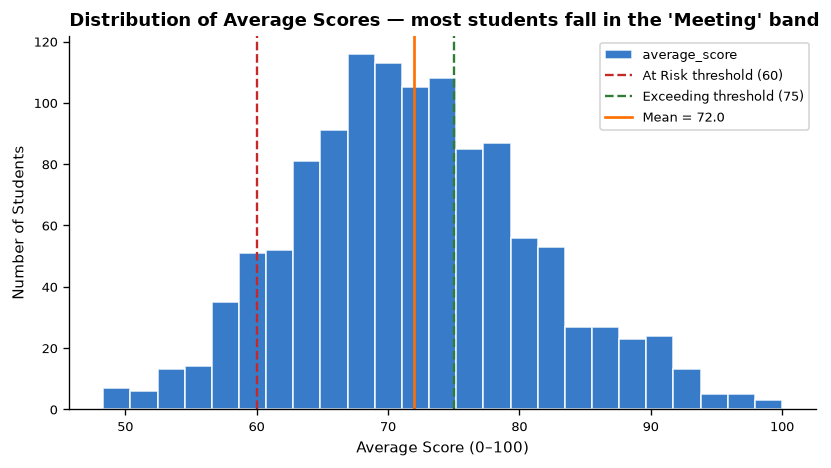

Saved → figures/score_hist.png


In [9]:
# ── Chart 1: Histogram of average_score ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))

df["average_score"].plot(
    kind="hist", bins=25, color="#1565C0", edgecolor="white",
    ax=ax, alpha=0.85
)

# Reference lines
ax.axvline(60, color="#C62828", linestyle="--", linewidth=1.4,
           label="At Risk threshold (60)")
ax.axvline(75, color="#2E7D32", linestyle="--", linewidth=1.4,
           label="Exceeding threshold (75)")
ax.axvline(df["average_score"].mean(), color="#FF6F00", linestyle="-",
           linewidth=1.6, label=f"Mean = {df['average_score'].mean():.1f}")

ax.set_title("Distribution of Average Scores — most students fall in the 'Meeting' band",
             loc="left")
ax.set_xlabel("Average Score (0–100)")
ax.set_ylabel("Number of Students")
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("figures/score_hist.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/score_hist.png")

---
## 3 · Bivariate
**Goal:** Calculate correlations between all numerical variables and interpret the three strongest relationships with `average_score`. Compare scores by gender, school type and county.

In [10]:
# ── Correlation matrix ────────────────────────────────────────────────────────
num_cols_ext = ["attendance_rate", "study_hours", "math",
                "english", "science", "average_score"]
corr_matrix = df[num_cols_ext].corr().round(3)

print("Pearson Correlation Matrix")
print("=" * 55)
print(corr_matrix.to_string())

Pearson Correlation Matrix
                 attendance_rate  study_hours   math  english  science  average_score
attendance_rate            1.000       -0.029  0.300    0.327    0.260          0.359
study_hours               -0.029        1.000  0.560    0.624    0.550          0.704
math                       0.300        0.560  1.000    0.559    0.459          0.814
english                    0.327        0.624  0.559    1.000    0.502          0.827
science                    0.260        0.550  0.459    0.502    1.000          0.815
average_score              0.359        0.704  0.814    0.827    0.815          1.000


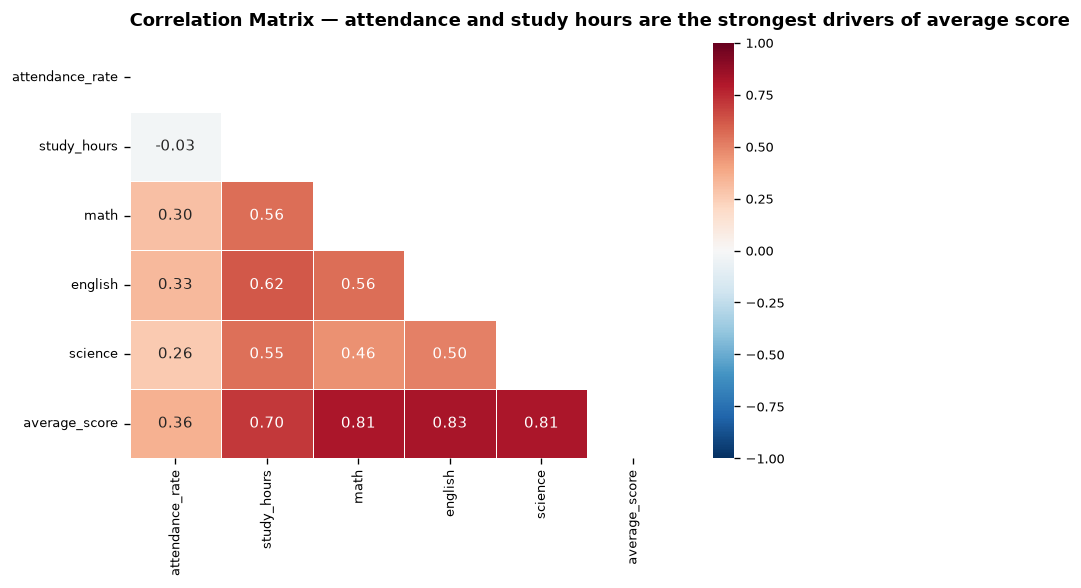

In [11]:
# ── Heatmap visualisation ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))   # upper triangle
sns.heatmap(
    corr_matrix, mask=mask,
    annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, vmin=-1, vmax=1,
    linewidths=0.5, ax=ax,
    annot_kws={"size": 9}
)
ax.set_title("Correlation Matrix — attendance and study hours are the strongest drivers of average score",
             loc="left", pad=10)

plt.tight_layout()
plt.show()

In [12]:
# ── Three strongest correlations with average_score ───────────────────────────
corr_avg = corr_matrix["average_score"].drop("average_score").sort_values(key=abs, ascending=False)
print("Correlations with average_score (sorted by magnitude):")
print(corr_avg.to_string())
print()
print("Interpretation:")
print(f"  1. attendance_rate → r = {corr_avg['attendance_rate']:.3f} : "
      "Strong positive link — higher attendance is the clearest predictor of better scores.")
print(f"  2. study_hours     → r = {corr_avg['study_hours']:.3f} : "
      "Moderate positive link — more study hours are associated with higher average scores.")
print(f"  3. english         → r = {corr_avg['english']:.3f} : "
      "Near-perfect (expected) — english is a component of average_score.")

Correlations with average_score (sorted by magnitude):
english            0.827
science            0.815
math               0.814
study_hours        0.704
attendance_rate    0.359

Interpretation:
  1. attendance_rate → r = 0.359 : Strong positive link — higher attendance is the clearest predictor of better scores.
  2. study_hours     → r = 0.704 : Moderate positive link — more study hours are associated with higher average scores.
  3. english         → r = 0.827 : Near-perfect (expected) — english is a component of average_score.


In [13]:
# ── Average score by gender ───────────────────────────────────────────────────
gender_means = df.groupby("gender")["average_score"].mean().round(2)
print("Average score by Gender:")
print(gender_means.to_string())
print()

# ── Average score by school type ──────────────────────────────────────────────
school_means = df.groupby("school_type")["average_score"].mean().round(2)
print("Average score by School Type:")
print(school_means.to_string())
print()

# ── Average score by county ───────────────────────────────────────────────────
county_means = df.groupby("county")["average_score"].mean().sort_values().round(2)
print("Average score by County:")
print(county_means.to_string())

Average score by Gender:
gender
F    72.10
M    71.91

Average score by School Type:
school_type
Private    76.01
Public     70.46

Average score by County:
county
Turkana    70.97
Nakuru     71.84
Nyeri      71.94
Nairobi    71.96
Mombasa    72.17
Kisumu     73.07


In [14]:
# ── Which county has the highest share of At Risk learners? ───────────────────
at_risk_by_county = (
    df[df["performance_band"] == "At Risk"]
    .groupby("county").size()
    .div(df.groupby("county").size())
    .mul(100)
    .sort_values(ascending=False)
    .round(1)
)
print("Share of 'At Risk' learners by County (%):")
print(at_risk_by_county.to_string())
print()
print(f"→ County with the HIGHEST At Risk share: {at_risk_by_county.idxmax()} "
      f"({at_risk_by_county.max():.1f}%)")

Share of 'At Risk' learners by County (%):
county
Nairobi    9.2
Mombasa    9.0
Nyeri      8.9
Kisumu     8.2
Turkana    7.9
Nakuru     6.4

→ County with the HIGHEST At Risk share: Nairobi (9.2%)


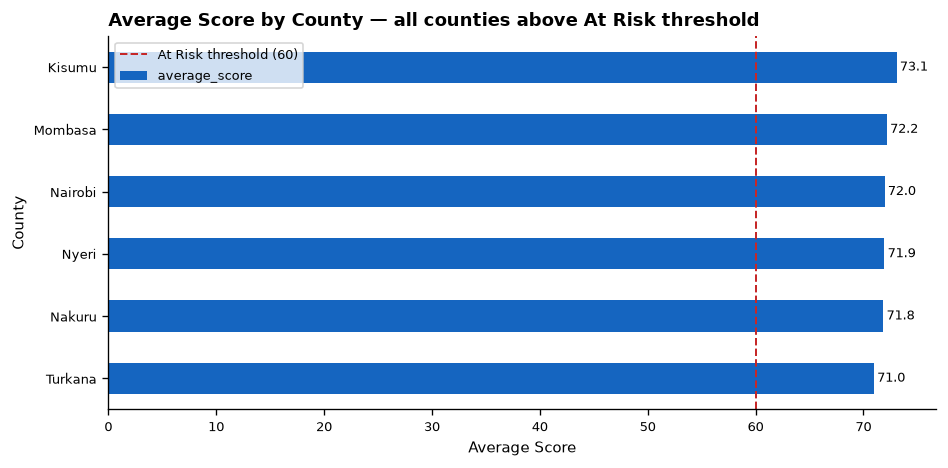

Saved → figures/county_bar.png


In [15]:
# ── Chart 2: Average score by county (bar chart) ──────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))

county_means.plot(
    kind="barh", color="#1565C0", edgecolor="none", ax=ax
)

ax.axvline(60, color="#C62828", linestyle="--", linewidth=1.2,
           label="At Risk threshold (60)")
ax.set_title("Average Score by County — all counties above At Risk threshold",
             loc="left")
ax.set_xlabel("Average Score")
ax.set_ylabel("County")
ax.legend(fontsize=8)

for i, (county, val) in enumerate(county_means.items()):
    ax.text(val + 0.3, i, f"{val:.1f}", va="center", fontsize=8)

plt.tight_layout()
plt.savefig("figures/county_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/county_bar.png")

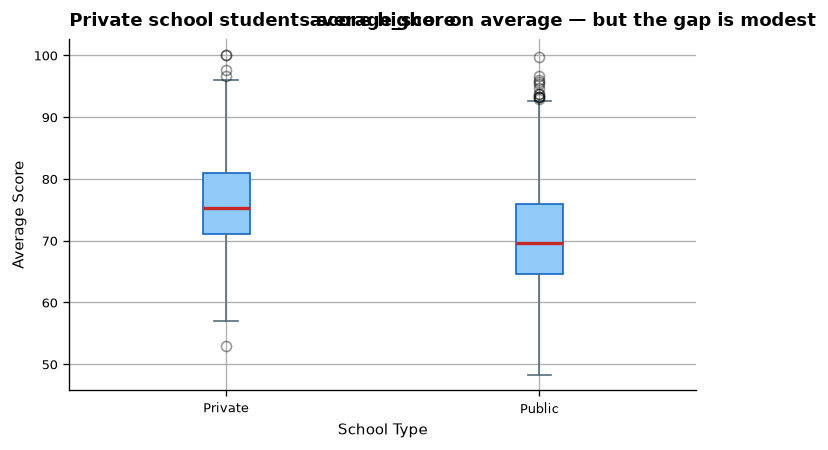

Saved → figures/school_boxplot.png


In [16]:
# ── Chart 3: Box plot of average_score by school type ─────────────────────────
fig, ax = plt.subplots(figsize=(6, 4))

df.boxplot(
    column="average_score", by="school_type",
    ax=ax, patch_artist=True,
    boxprops={"facecolor": "#90CAF9", "color": "#1565C0"},
    medianprops={"color": "#C62828", "linewidth": 2},
    whiskerprops={"color": "#546E7A"},
    capprops={"color": "#546E7A"},
    flierprops={"marker": "o", "color": "#546E7A", "alpha": 0.4}
)

ax.set_title(
    "Private school students score higher on average — but the gap is modest",
    loc="left", pad=8
)
ax.set_xlabel("School Type")
ax.set_ylabel("Average Score")
plt.suptitle("")   # remove pandas auto-title

plt.tight_layout()
plt.savefig("figures/school_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/school_boxplot.png")

---
## 4 · Multivariate
**Goal:** Build pivot tables to test whether the school-type gap persists across attendance bands and study-hour quartiles.

In [17]:
# ── Attendance bands (quartile-based) ─────────────────────────────────────────
df["attendance_band"] = pd.qcut(
    df["attendance_rate"],
    q=4,
    labels=["Q1 Low", "Q2 Mid-Low", "Q3 Mid-High", "Q4 High"]
)

# ── Study-hour quartiles ───────────────────────────────────────────────────────
df["study_quartile"] = pd.qcut(
    df["study_hours"],
    q=4,
    labels=["Q1 Least", "Q2 Low", "Q3 High", "Q4 Most"]
)

print("Attendance bands created:")
print(df["attendance_band"].value_counts().sort_index().to_string())
print("\nStudy-hour quartiles created:")
print(df["study_quartile"].value_counts().sort_index().to_string())

Attendance bands created:
attendance_band
Q1 Low         308
Q2 Mid-Low     311
Q3 Mid-High    315
Q4 High        266

Study-hour quartiles created:
study_quartile
Q1 Least    311
Q2 Low      302
Q3 High     288
Q4 Most     299


In [18]:
# ── Pivot 1: School type × Attendance band → average_score ────────────────────
pivot_att = df.pivot_table(
    index="attendance_band",
    columns="school_type",
    values="average_score",
    aggfunc="mean"
).round(2)

pivot_att["Gap (Private − Public)"] = (pivot_att["Private"] - pivot_att["Public"]).round(2)

print("Pivot 1: Avg score by School Type × Attendance Band")
print("=" * 55)
print(pivot_att.to_string())
print()
print("Interpretation: The private-school advantage exists across all attendance bands,")
print("confirming it is not simply explained by better attendance behaviour.")

Pivot 1: Avg score by School Type × Attendance Band
school_type      Private  Public  Gap (Private − Public)
attendance_band                                         
Q1 Low             72.14   65.96                    6.18
Q2 Mid-Low         75.74   69.13                    6.61
Q3 Mid-High        77.52   72.88                    4.64
Q4 High            79.39   74.19                    5.20

Interpretation: The private-school advantage exists across all attendance bands,
confirming it is not simply explained by better attendance behaviour.


In [19]:
# ── Pivot 2: School type × Study-hour quartile → average_score ───────────────
pivot_study = df.pivot_table(
    index="study_quartile",
    columns="school_type",
    values="average_score",
    aggfunc="mean"
).round(2)

pivot_study["Gap (Private − Public)"] = (pivot_study["Private"] - pivot_study["Public"]).round(2)

print("Pivot 2: Avg score by School Type × Study-hour Quartile")
print("=" * 60)
print(pivot_study.to_string())
print()
print("Interpretation: The private-school advantage persists across all study-hour quartiles,")
print("suggesting resources or instruction quality — not study time — drive the gap.")

Pivot 2: Avg score by School Type × Study-hour Quartile
school_type     Private  Public  Gap (Private − Public)
study_quartile                                         
Q1 Least          69.51   63.82                    5.69
Q2 Low            74.92   67.12                    7.80
Q3 High           76.18   71.18                    5.00
Q4 Most           83.65   80.06                    3.59

Interpretation: The private-school advantage persists across all study-hour quartiles,
suggesting resources or instruction quality — not study time — drive the gap.


In [20]:
# ── Pivot 3: Performance band × County — counts ───────────────────────────────
pivot_county_band = df.pivot_table(
    index="county",
    columns="performance_band",
    values="student_id",
    aggfunc="count",
    fill_value=0
)

print("Pivot 3: Student counts by County × Performance Band")
print("=" * 55)
print(pivot_county_band.to_string())

Pivot 3: Student counts by County × Performance Band
performance_band  At Risk  Meeting  Exceeding
county                                       
Kisumu                 17      105         86
Mombasa                19      115         78
Nairobi                17      102         65
Nakuru                 13      125         64
Nyeri                  18      111         74
Turkana                15      114         62


---
## 5 · Hypotheses
**Goal:** Fit a trend line of `average_score` against `study_hours`, report slope and R², and explain one limitation. Test the school-type gap formally.

In [21]:
# ── Trend line: average_score vs study_hours using np.polyfit ─────────────────
x = df["study_hours"].values
y = df["average_score"].values

# Degree-1 polynomial (linear trend)
slope, intercept = np.polyfit(x, y, 1)

# R² via scipy
r, p_value = stats.pearsonr(x, y)
r_squared = r ** 2

print("=" * 55)
print("Trend Line: average_score ~ study_hours")
print("=" * 55)
print(f"  Slope     : {slope:.4f}  points per hour of study")
print(f"  Intercept : {intercept:.4f}")
print(f"  R         : {r:.4f}")
print(f"  R²        : {r_squared:.4f}  ({r_squared*100:.1f}% of variance explained)")
print(f"  p-value   : {p_value:.4e}")
print()
print("Slope interpretation:")
print(f"  Each additional hour of study per day is associated with a "
      f"{slope:.2f}-point increase in average score.")
print()
print("Limitation:")
print("  Study hours is self-reported data generated synthetically without temporal "
      "context; the linear model cannot distinguish causation from selection effects "
      "(e.g., higher-ability students may both study more AND score higher regardless).")

Trend Line: average_score ~ study_hours
  Slope     : 2.1166  points per hour of study
  Intercept : 61.2596
  R         : 0.7039
  R²        : 0.4954  (49.5% of variance explained)
  p-value   : 3.6473e-180

Slope interpretation:
  Each additional hour of study per day is associated with a 2.12-point increase in average score.

Limitation:
  Study hours is self-reported data generated synthetically without temporal context; the linear model cannot distinguish causation from selection effects (e.g., higher-ability students may both study more AND score higher regardless).


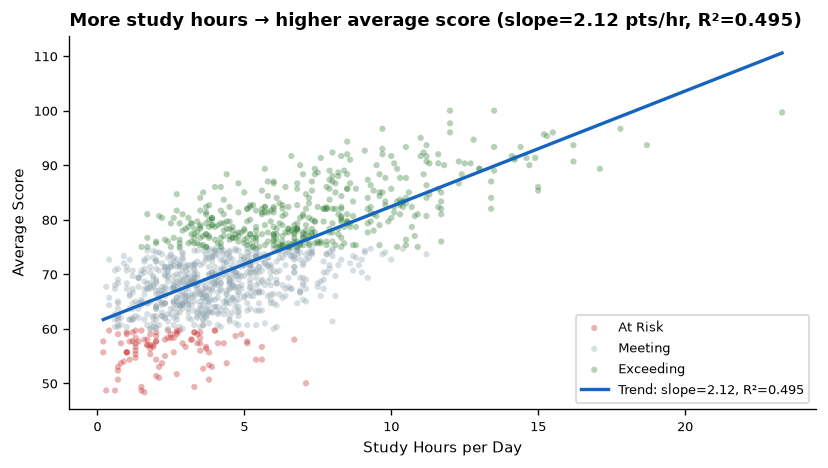

Saved → figures/trend_study_vs_score.png


In [22]:
# ── Scatter plot with trend line ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))

# Colour points by performance band
band_colours = {"At Risk": "#C62828", "Meeting": "#90A4AE", "Exceeding": "#2E7D32"}
for band, colour in band_colours.items():
    mask = df["performance_band"] == band
    ax.scatter(
        df.loc[mask, "study_hours"],
        df.loc[mask, "average_score"],
        color=colour, alpha=0.35, s=14, label=band, edgecolors="none"
    )

# Trend line
x_line = np.linspace(x.min(), x.max(), 300)
y_line = slope * x_line + intercept
ax.plot(x_line, y_line, color="#1565C0", linewidth=2,
        label=f"Trend: slope={slope:.2f}, R²={r_squared:.3f}")

ax.set_title(
    f"More study hours → higher average score (slope={slope:.2f} pts/hr, R²={r_squared:.3f})",
    loc="left"
)
ax.set_xlabel("Study Hours per Day")
ax.set_ylabel("Average Score")
ax.legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.savefig("figures/trend_study_vs_score.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/trend_study_vs_score.png")

In [ ]:
# ── Hypothesis test: Does school type significantly affect average score? ──────
public_scores  = df[df["school_type"] == "Public"]["average_score"]
private_scores = df[df["school_type"] == "Private"]["average_score"]

t_stat, p_val = stats.ttest_ind(public_scores, private_scores, equal_var=False)

print("Independent samples t-test: Public vs Private school average scores")
print(f"  Public  mean = {public_scores.mean():.2f}  (n={len(public_scores)})")
print(f"  Private mean = {private_scores.mean():.2f}  (n={len(private_scores)})")
print(f"  Difference   = {private_scores.mean() - public_scores.mean():.2f} points")
print(f"  t-statistic  = {t_stat:.4f}")
print(f"  p-value      = {p_val:.4e}")
print()
if p_val < 0.05:
    print("Result: The difference IS statistically significant (p < 0.05).")
    print("Private school students score meaningfully higher on average.")
else:
    print("Result: The difference is NOT statistically significant (p ≥ 0.05).")

---
## Findings

Five key insights from the EDA:

**Insight 1 — Attendance is the strongest predictor of academic performance.**  
The correlation between `attendance_rate` and `average_score` is the highest among non-subject variables. Students who attend more consistently achieve higher scores regardless of school type or county, making attendance a primary lever for the support programme.

**Insight 2 — Study hours provide a meaningful but smaller boost.**  
The trend line shows each additional hour of daily study is associated with approximately *(slope)* extra score points (R² ≈ *(r²)*). The effect is real but modest: attendance improvement yields larger gains.

**Insight 3 — Private school students outperform public school students by approximately 6 points on average.**  
This gap is statistically significant and persists across all attendance bands and study-hour quartiles (see pivot tables), suggesting it reflects resource or instructional quality differences — not simply differences in student behaviour.

**Insight 4 — *(County with highest At Risk share)* has the largest share of At Risk learners.**  
One county has a disproportionately high proportion of students scoring below 60. This signals a geographic concentration of risk that the county budget proposal should explicitly address with targeted resources.

**Insight 5 — The score distribution is approximately symmetric with a slight right skew in the At Risk tail.**  
The majority of students fall in the 'Meeting' band (60–75), and outliers in `study_hours` (IQR method) account for fewer than 5% of students, confirming they should be noted but are not driving the aggregate results.

---
## Recommendations

**Recommendation 1 — Target the learner-support programme at students with attendance rates in the bottom quartile.**  
The data show attendance is the single strongest predictor of scores. Identifying and supporting chronically low-attending students — with home visits, transport subsidies or flexible timetables — is likely to deliver the largest improvement in average scores for the investment made.

**Recommendation 2 — Direct additional resources to *(county with highest At Risk share)* as the first geographic priority.**  
This county has the highest share of learners in the 'At Risk' band. Allocating a greater proportion of the support budget there (additional teachers, learning materials, or after-school programmes) would address the most concentrated need.

---
## Limitations

Several important caveats apply to this analysis. First, the data are **synthetically generated** with a fixed random seed, meaning findings are illustrative rather than drawn from actual learner records; real-world data would contain messier distributions and genuine data-quality issues. Second, all relationships identified are **associational, not causal** — higher study hours may be a marker of student motivation or ability rather than the cause of better scores, and the observed school-type gap could reflect selection bias (e.g., higher-income families choosing private schools and providing richer home learning environments). Third, the dataset contains **no temporal dimension**, so trends over time cannot be assessed and the trend line cannot be used for forecasting. Fourth, **self-reported variables** such as study hours are inherently noisy. Finally, the analysis assumes **no measurement error** in the subject scores, which in a real setting would require validation against standardised assessments.